# Forecasting the 2026 U.S. Holiday Retail Season
### Classical vs. machine-learning vs. LLM forecasters - and a planning rule for small retailers

**UCLA Anderson · Time Series Analysis and Forecasting (Dr. William Yu) · Group project, October 2026**
Team: Charlotte Zhu, Shihan Wang, Jing Chang, Rachel Liu

This notebook is **self-contained**: it downloads the data from FRED, fits every model, runs the 11-season backtest,
evaluates the forecasts and produces the 2026 holiday forecast. Run all cells top to bottom (about 3-5 minutes).
It works in Jupyter or Google Colab.

The same code powers our interactive dashboard and lives as a full project on GitHub:
https://github.com/RachelLiu13/holiday-retail-forecast

**Research questions**
1. How much will Americans spend in the 2026 holiday season (Nov+Dec), by retail category?
2. Can forecasting models beat the retailer's habit of ordering *"same as last year"*? Which model is best?
3. Can large language models (Claude, GPT) forecast as well as statistical models - or do they just remember the data?
4. Does consumer sentiment improve the forecast?
5. How can a small retailer turn a national forecast into an order?

In [1]:
# In Google Colab, uncomment the next line first:
# !pip install -q xgboost statsmodels joblib

import itertools, warnings, urllib.request, json, re, os, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from joblib import Parallel, delayed
from scipy.stats import norm, wilcoxon
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings('ignore')
os.environ['PYTHONWARNINGS'] = 'ignore'  # also silence convergence warnings in the parallel worker processes
pd.set_option('display.width', 160)

BLUE, ORANGE, GRAY, INK, GRID = '#2a78d6', '#eb6834', '#8a8984', '#0b0b0b', '#e4e3df'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': GRID, 'axes.edgecolor': GRID, 'figure.dpi': 110, 'lines.linewidth': 2})

## 1. Settings

In [2]:
CATEGORIES = {
    "total":       {"fred": "RSXFSN",        "label": "Total Retail (ex. food services)"},
    "clothing":    {"fred": "MRTSSM448USN",  "label": "Clothing & Accessories Stores"},
    "electronics": {"fred": "MRTSSM443USN",  "label": "Electronics & Appliance Stores"},
    "hobby":       {"fred": "MRTSSM451USN",  "label": "Sporting Goods, Hobby, Book & Music Stores"},
    "general":     {"fred": "MRTSSM452USN",  "label": "General Merchandise Stores"},
    "ecommerce":   {"fred": "MRTSSM4541USN", "label": "E-commerce (Electronic Shopping & Mail-Order)"},
    "grocery":     {"fred": "MRTSSM445USN",  "label": "Grocery Stores (control: no holiday peak)"},
}


SENTIMENT = "UMCSENT"


HORIZON = 4


BACKTEST_YEARS = list(range(2015, 2026))


FINAL_ORIGIN = "2026-08-01"


TRAIN_START = "1999-01-01"


HOLIDAY_MONTHS = (11, 12)

WORK = Path('holiday_forecast_data'); WORK.mkdir(exist_ok=True)
RAW = PROCESSED = OUTPUTS = WORK

## 2. Data

U.S. Census Bureau **Monthly Retail Trade**, *not seasonally adjusted* (the holiday spike is exactly what we want to
forecast), $ millions, via FRED - plus the University of Michigan **Consumer Sentiment** index as a customer-side
indicator. The quality check confirms there are no missing months or duplicate records.

In [3]:
FRED_CSV = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={}"


def download(series_id: str, refresh: bool = False) -> pd.Series:
    path = RAW / f"{series_id}.csv"
    if refresh or not path.exists():
        RAW.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(FRED_CSV.format(series_id), timeout=60) as r:
            path.write_bytes(r.read())
    df = pd.read_csv(path)
    df.columns = ["date", series_id]
    df["date"] = pd.to_datetime(df["date"])
    s = pd.to_numeric(df[series_id], errors="coerce")  # FRED marks gaps with "."
    return pd.Series(s.values, index=df["date"], name=series_id)


def build_panel(refresh: bool = False) -> pd.DataFrame:
    cols = {key: download(meta["fred"], refresh) for key, meta in CATEGORIES.items()}
    cols["sentiment"] = download(SENTIMENT, refresh)
    panel = pd.DataFrame(cols).sort_index()
    panel.index.name = "date"
    panel = panel[panel.index >= "1992-01-01"]
    PROCESSED.mkdir(parents=True, exist_ok=True)
    panel.to_csv(PROCESSED / "monthly_panel.csv")
    return panel


def quality_report(panel: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for key in CATEGORIES:
        s = panel[key]
        valid = s.dropna()
        full = pd.date_range(valid.index.min(), valid.index.max(), freq="MS")
        rows.append({
            "series": key,
            "first": valid.index.min().date(),
            "last": valid.index.max().date(),
            "months": len(valid),
            "missing_inside_range": len(full.difference(valid.index)),
            "duplicates": int(s.index.duplicated().sum()),
            "min": valid.min(),
            "max": valid.max(),
        })
    return pd.DataFrame(rows)


panel = build_panel(refresh=True)
quality_report(panel)

,series,first,last,months,missing_inside_range,duplicates,min,max
0,total,1992-01-01,2026-09-01,417,0,0,126717.0,694088.0
1,clothing,1992-01-01,2026-08-01,416,0,0,2532.0,39105.0
2,electronics,1992-01-01,2026-08-01,416,0,0,2817.0,15243.0
3,hobby,1992-01-01,2026-08-01,416,0,0,2534.0,11888.0
4,general,1992-01-01,2026-08-01,416,0,0,14892.0,96014.0
5,ecommerce,1992-01-01,2026-08-01,416,0,0,2245.0,139317.0
6,grocery,1992-01-01,2026-08-01,416,0,0,27551.0,90541.0


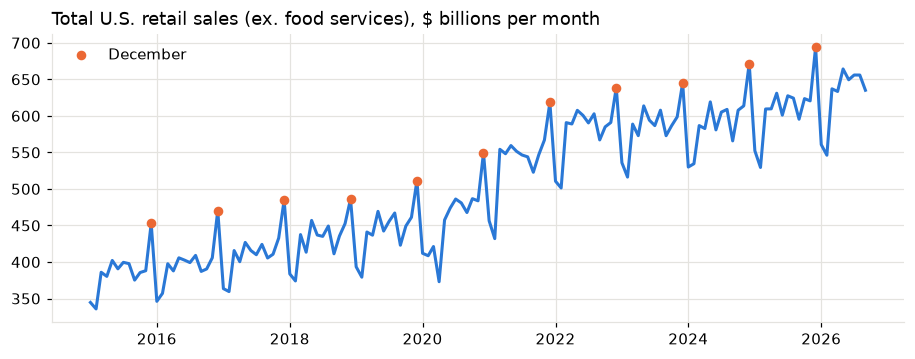

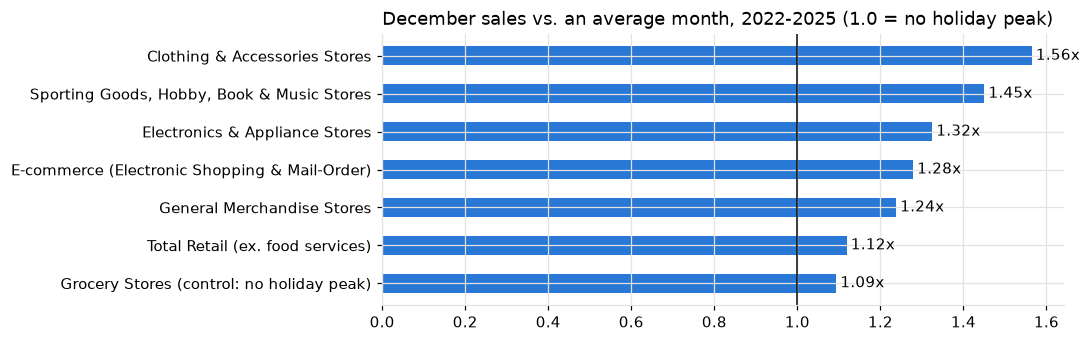

E-commerce share of retail, Jan-Aug of each year (%):
2015     8.31
2016     9.10
2017     9.88
2018    10.55
2019    11.34
2020    14.83
2021    14.69
2022    14.74
2023    15.94
2024    16.48
2025    16.86
2026    17.43


In [4]:
fig, ax = plt.subplots(figsize=(10, 3.4))
s = panel['total'].loc['2015':]
ax.plot(s.index, s / 1000, color=BLUE)
dec = s[s.index.month == 12]
ax.scatter(dec.index, dec / 1000, color=ORANGE, zorder=3, s=28, label='December')
ax.set_title('Total U.S. retail sales (ex. food services), $ billions per month', loc='left'); ax.legend(frameon=False); plt.show()

prof = {}
for c in CATEGORIES:
    s = panel[c].loc['2022':'2025']
    prof[CATEGORIES[c]['label']] = (s.groupby(s.index.month).sum() / s.sum() * 12)
dec = pd.DataFrame(prof).loc[12].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(dec.index, dec.values, color=BLUE, height=0.5); ax.axvline(1, color=INK, lw=1)
for i, v in enumerate(dec.values): ax.text(v + 0.01, i, f'{v:.2f}x', va='center')
ax.set_title('December sales vs. an average month, 2022-2025 (1.0 = no holiday peak)', loc='left'); plt.show()

share = pd.Series({y: panel.loc[f'{y}-01':f'{y}-08', 'ecommerce'].sum() / panel.loc[f'{y}-01':f'{y}-08', 'total'].sum()
                   for y in range(2015, 2027)})
print('E-commerce share of retail, Jan-Aug of each year (%):'); print((share * 100).round(2).to_string())

## 3. Models

All statistical models work on **log sales** (so seasonal swings scale with the level), and the March-June 2020
lockdown months are treated as outliers in training (replaced with their pre-pandemic trajectory using only data
available at the time).

| Model | Idea |
|---|---|
| Seasonal Naive | this December = last December - the retailer's habit, our baseline |
| Naive + Growth | last year's month × recent year-over-year growth |
| ETS | damped-trend exponential smoothing with monthly seasonality |
| SARIMA | seasonal ARIMA, order chosen by AIC from 16 candidates on training data only |
| SARIMAX + Sentiment | SARIMA + consumer sentiment lagged 4 months (always known at forecast time) |
| XGBoost | one gradient-boosted model pooled across categories, predicting year-over-year growth |
| Ensemble | average of SARIMA, ETS and XGBoost in log space |

In [5]:
COVID_MONTHS = pd.date_range("2020-03-01", "2020-06-01", freq="MS")


def future_index(origin: pd.Timestamp, h: int = HORIZON) -> pd.DatetimeIndex:
    return pd.date_range(origin + pd.offsets.MonthBegin(1), periods=h, freq="MS")


def clean_covid(y: pd.Series) -> pd.Series:
    """Treat the March-June 2020 lockdown months as outliers for model training.

    Each lockdown month is replaced by the same month of 2019 scaled by the Jan-Feb 2020
    year-over-year growth, i.e. what the series was on track to do before the shock. Only
    data before the shock is used, so this never leaks future information.
    """
    y = y.copy()
    if y.index.max() < COVID_MONTHS[0]:
        return y
    pre = y.loc["2020-01-01":"2020-02-01"].sum() / y.loc["2019-01-01":"2019-02-01"].sum()
    for m in COVID_MONTHS:
        if m in y.index:
            y.loc[m] = y.loc[m - pd.DateOffset(years=1)] * pre
    return y


def _prep(y: pd.Series) -> pd.Series:
    y = clean_covid(y.dropna())
    y = y[y.index >= TRAIN_START]
    return np.log(y).asfreq("MS")


# ---------------------------------------------------------------- baselines

def fc_snaive(y: pd.Series, origin: pd.Timestamp) -> pd.DataFrame:
    """Seasonal naive: next December = last December."""
    idx = future_index(origin)
    return pd.DataFrame({"mean": [y.loc[d - pd.DateOffset(years=1)] for d in idx]}, index=idx)


def fc_snaive_growth(y: pd.Series, origin: pd.Timestamp) -> pd.DataFrame:
    """Same month last year x recent year-over-year growth (average of the last 3 months).

    This is the rule of thumb many retailers actually use: 'last year plus current trend'.
    """
    idx = future_index(origin)
    recent = [np.log(y.loc[origin - pd.DateOffset(months=k)] /
                     y.loc[origin - pd.DateOffset(months=k, years=1)]) for k in range(3)]
    g = float(np.mean(recent))
    return pd.DataFrame({"mean": [y.loc[d - pd.DateOffset(years=1)] * np.exp(g) for d in idx]},
                        index=idx)


# ---------------------------------------------------------------- statistical models

def fc_ets(y: pd.Series, origin: pd.Timestamp) -> pd.DataFrame:
    """ETS(A,Ad,A) on log sales: additive error, damped trend, additive monthly seasonality."""
    ly = _prep(y.loc[:origin])
    res = ETSModel(ly, error="add", trend="add", damped_trend=True,
                   seasonal="add", seasonal_periods=12).fit(disp=False, maxiter=2000)
    pred = res.get_prediction(start=len(ly), end=len(ly) + HORIZON - 1).summary_frame(alpha=0.2)
    idx = future_index(origin)
    return pd.DataFrame({"mean": np.exp(pred["mean"].values),
                         "lo80": np.exp(pred["pi_lower"].values),
                         "hi80": np.exp(pred["pi_upper"].values)}, index=idx)


SARIMA_GRID = list(itertools.product([0, 1], [0, 1], [0, 1], [0, 1]))  # p, q, P, Q


def select_sarima_order(ly: pd.Series):
    """Pick (p,1,q)(P,1,Q)12 by AIC on the training window only."""
    best = None
    for p, q, P, Q in SARIMA_GRID:
        try:
            r = SARIMAX(ly, order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False, maxiter=200)
        except Exception:
            continue
        if best is None or r.aic < best[0]:
            best = (r.aic, (p, 1, q), (P, 1, Q, 12))
    return best[1], best[2]


def _sarimax_fc(ly, origin, order, sorder, exog=None, exog_future=None) -> pd.DataFrame:
    res = SARIMAX(ly, exog=exog, order=order, seasonal_order=sorder).fit(disp=False, maxiter=200)
    f = res.get_forecast(HORIZON, exog=exog_future)
    ci = f.conf_int(alpha=0.2)
    idx = future_index(origin)
    return pd.DataFrame({"mean": np.exp(f.predicted_mean.values),
                         "lo80": np.exp(ci.iloc[:, 0].values),
                         "hi80": np.exp(ci.iloc[:, 1].values)}, index=idx)


def fc_sarima(y: pd.Series, origin: pd.Timestamp, order=None) -> tuple[pd.DataFrame, tuple]:
    ly = _prep(y.loc[:origin])
    if order is None:
        order = select_sarima_order(ly)
    return _sarimax_fc(ly, origin, *order), order


def fc_sarimax_sentiment(y: pd.Series, sent: pd.Series, origin: pd.Timestamp, order) -> pd.DataFrame:
    ly = _prep(y.loc[:origin])
    # Log sentiment lagged HORIZON months: every value a 4-month-ahead forecast needs is
    # already published at the origin, so the model never peeks at future sentiment.
    ext = sent.reindex(sent.index.union(future_index(origin)))
    ext.loc[ext.index > origin] = np.nan
    ex = np.log(ext).shift(HORIZON)
    ex_train = ex.reindex(ly.index)
    keep = ex_train.notna()
    ly, ex_train = ly[keep], ex_train[keep]
    ex_future = ex.reindex(future_index(origin))
    return _sarimax_fc(ly, origin, *order, exog=ex_train.values, exog_future=ex_future.values)


# ---------------------------------------------------------------- machine learning

XGB_PARAMS = dict(n_estimators=400, max_depth=3, learning_rate=0.03, subsample=0.8,
                  colsample_bytree=0.8, min_child_weight=5, reg_lambda=1.0, random_state=42)


def _xgb_rows(ly: pd.Series, lsent: pd.Series, cat_code: int, origins, with_target: bool):
    """One row per (origin month t, horizon h).

    Target: year-over-year log growth of month t+h, i.e. log y[t+h] - log y[t+h-12].
    The forecast is then last year's same month x exp(predicted growth). All features are
    known at month t.
    """
    g = ly - ly.shift(12)                    # YoY log growth series
    rows = []
    for t in origins:
        if t - pd.DateOffset(months=14) < ly.index[0]:
            continue
        feats_t = {
            "g0": g.get(t), "g1": g.get(t - pd.DateOffset(months=1)),
            "g2": g.get(t - pd.DateOffset(months=2)),
            "g12": g.loc[t - pd.DateOffset(months=11):t].mean(),
            "mom3": ly.get(t) - ly.get(t - pd.DateOffset(months=3)),
            "sent_yoy": lsent.get(t) - lsent.get(t - pd.DateOffset(months=12)),
            "sent_lvl": lsent.get(t),
        }
        for h in range(1, HORIZON + 1):
            d = t + pd.DateOffset(months=h)
            r = dict(feats_t, h=h, month=d.month, cat=cat_code, t=t, d=d)
            # last year's growth for the same target month captures shifting holiday timing
            r["g_ly_target"] = g.get(d - pd.DateOffset(years=1))
            if with_target:
                if d not in ly.index:
                    continue
                r["y"] = ly.loc[d] - ly.loc[d - pd.DateOffset(years=1)]
            rows.append(r)
    return pd.DataFrame(rows)


FEATURES = ["g0", "g1", "g2", "g12", "mom3", "sent_yoy", "sent_lvl", "h", "month", "g_ly_target"]


def fc_xgb_global(panel: pd.DataFrame, cats: list[str], origin: pd.Timestamp) -> dict:
    """One XGBoost model pooled across all categories (category one-hot as a feature)."""
    lsent = np.log(panel["sentiment"])
    train, pred, base = [], [], {}
    for i, c in enumerate(cats):
        ly = _prep(panel[c].loc[:origin])
        hist = [t for t in ly.index if t + pd.DateOffset(months=1) <= origin]
        tr = _xgb_rows(ly, lsent, i, hist, with_target=True)
        train.append(tr[tr["d"] <= origin])           # targets must be observed by the origin
        pred.append(_xgb_rows(ly, lsent, i, [origin], with_target=False))
        base[c] = ly
    train = pd.concat(train, ignore_index=True).dropna(subset=["y"])
    pred = pd.concat(pred, ignore_index=True)
    X = pd.get_dummies(train[FEATURES + ["cat"]], columns=["cat"], dtype=float)
    Xp = pd.get_dummies(pred[FEATURES + ["cat"]], columns=["cat"], dtype=float).reindex(columns=X.columns, fill_value=0)
    model = xgb.XGBRegressor(**XGB_PARAMS)
    model.fit(X, train["y"])
    pred["g_hat"] = model.predict(Xp)
    out = {}
    for i, c in enumerate(cats):
        p = pred[pred["cat"] == i].sort_values("h")
        ly_raw = np.log(panel[c].dropna())  # use the real (uncleaned) last-year value as the base
        vals = [np.exp(ly_raw.loc[d - pd.DateOffset(years=1)] + gh) for d, gh in zip(p["d"], p["g_hat"])]
        out[c] = pd.DataFrame({"mean": vals}, index=future_index(origin))
    importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
    return out, importance


## 4. Rolling-origin backtest (11 holiday seasons, 2015-2025)

For each year, every model stands at the **end of August**, is fit only on data available then, and forecasts
**September-December**. Same origin, horizon and information for every model. The same code then runs from
August 2026 to produce the live 2026 forecast. *(About 2-4 minutes.)*

In [6]:
CATS = list(CATEGORIES)
ENSEMBLE_OF = ['SARIMA', 'ETS', 'XGBoost']


def _stat_models(panel, cat, origin):
    y = panel[cat].dropna()
    out = {"Seasonal Naive": fc_snaive(y, origin),
           "Naive + Growth": fc_snaive_growth(y, origin),
           "ETS": fc_ets(y, origin)}
    sar, order = fc_sarima(y, origin)
    out["SARIMA"] = sar
    out["SARIMAX + Sentiment"] = fc_sarimax_sentiment(y, panel["sentiment"].dropna(), origin, order)
    return cat, origin, out, order


def run_origin_set(panel, origins, n_jobs=-1):
    jobs = [(c, o) for o in origins for c in CATS]
    stat = Parallel(n_jobs=n_jobs)(delayed(_stat_models)(panel, c, o) for c, o in jobs)
    rows, orders, importances = [], [], []
    for cat, origin, out, order in stat:
        orders.append({"category": cat, "origin": origin.date(), "order": str(order[0]), "seasonal_order": str(order[1])})
        for model, df in out.items():
            rows.append(df.assign(model=model, category=cat, origin=origin))
    for origin in origins:
        xg, imp = fc_xgb_global(panel, CATS, origin)
        importances.append(imp.rename(origin.date()))
        for cat, df in xg.items():
            rows.append(df.assign(model="XGBoost", category=cat, origin=origin))
    fc = pd.concat(rows).rename_axis("date").reset_index()
    # Ensemble: geometric mean of the three main model families (average in log space)
    ens = (fc[fc.model.isin(ENSEMBLE_OF)]
           .assign(logm=lambda d: np.log(d["mean"]))
           .groupby(["category", "origin", "date"], as_index=False)["logm"].mean())
    ens["mean"] = np.exp(ens.pop("logm"))
    ens["model"] = "Ensemble"
    fc = pd.concat([fc, ens], ignore_index=True)
    fc["h"] = ((fc["date"].dt.year - fc["origin"].dt.year) * 12 + fc["date"].dt.month - fc["origin"].dt.month)
    return fc, pd.DataFrame(orders), pd.concat(importances, axis=1)


def attach_actuals(fc, panel):
    long = panel[CATS].stack().rename("actual").reset_index().rename(columns={"level_1": "category"})
    return fc.merge(long, on=["date", "category"], how="left")


# Some SARIMA candidates in the AIC search do not converge; that is expected and handled (AIC picks
# among the ones that fit). Silence those warnings inside the parallel worker processes.
_stat_models_verbose = _stat_models
def _stat_models(*args):
    import warnings
    warnings.simplefilter('ignore')
    return _stat_models_verbose(*args)


origins = [pd.Timestamp(f'{y}-08-01') for y in BACKTEST_YEARS]
fc, orders, importance = run_origin_set(panel, origins)
bt = attach_actuals(fc, panel)
f26, orders26, _ = run_origin_set(panel, [pd.Timestamp(FINAL_ORIGIN)])
f26 = attach_actuals(f26, panel)
print('backtest forecasts:', len(bt), '| 2026 forecasts:', len(f26))
orders.groupby('category')[['order', 'seasonal_order']].agg(lambda s: s.value_counts().index[0])

backtest forecasts: 2156 | 2026 forecasts: 196


,order,seasonal_order
category,,
clothing,"(0, 1, 1)","(1, 1, 1, 12)"
ecommerce,"(1, 1, 1)","(1, 1, 1, 12)"
electronics,"(0, 1, 1)","(0, 1, 1, 12)"
general,"(1, 1, 1)","(0, 1, 1, 12)"
grocery,"(1, 1, 1)","(1, 1, 1, 12)"
hobby,"(0, 1, 1)","(1, 1, 1, 12)"
total,"(1, 1, 1)","(1, 1, 1, 12)"


## 5. Can AI chatbots forecast? (LLM experiment)

We gave **Claude Opus 5.5** and **OpenAI GPT-5.5** the same 10-year monthly history in a prompt and asked for the next
4 months as JSON. **Memorization control:** an LLM may have read the real Census figures in training, so the main test is
*anonymized* - an index (first month = 100) labelled only by calendar month, with no category name and no year. For
Claude we also ran *named* prompts (real dates, category, dollars). If named prompts do much better on past seasons,
that is hindsight, not forecasting skill.

Calling the APIs costs money and needs keys, so by default this notebook **loads the forecasts we saved** from the
project repository. Set `RUN_LLM = True` (and provide `ANTHROPIC_API_KEY` / `OPENAI_API_KEY`) to regenerate them.

In [7]:
HISTORY_MONTHS = 120


CLAUDE_MODEL = "claude-opus-5-5"


MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


SYSTEM = (
    "You are a careful time-series forecaster. You are given a monthly history and must "
    "forecast the next 4 months. Use only the numbers provided. Think about level, trend, "
    "and month-of-year seasonality, then return your forecast in the requested JSON format."
)


SCHEMA = {
    "type": "object",
    "properties": {
        "reasoning": {"type": "string", "description": "2-4 sentences on the pattern you used"},
        "forecast": {"type": "array", "items": {"type": "number"}, "description": "exactly 4 values, in order"},
    },
    "required": ["reasoning", "forecast"],
    "additionalProperties": False,
}


def build_prompt(y: pd.Series, origin: pd.Timestamp, category: str, framing: str):
    """Return (prompt text, scale factor to convert the answer back to $ millions)."""
    hist = y.loc[:origin].iloc[-HISTORY_MONTHS:]
    future = future_index(origin)
    if framing == "anonymized":
        scale = hist.iloc[0] / 100.0
        vals = hist / scale
        lines = [f"{MONTHS[d.month - 1]}: {v:.1f}" for d, v in zip(hist.index, vals)]
        targets = ", ".join(MONTHS[d.month - 1] for d in future)
        text = (
            f"Below are {len(hist)} consecutive months of an anonymous monthly sales index "
            f"(first month = 100). Only the calendar month is shown; the series runs oldest "
            f"to newest.\n\n" + "\n".join(lines) +
            f"\n\nForecast the next 4 months ({targets}) on the same index scale."
        )
        return text, scale
    label = CATEGORIES[category]["label"]
    lines = [f"{d:%Y-%m}: {v:,.0f}" for d, v in zip(hist.index, hist)]
    targets = ", ".join(f"{d:%Y-%m}" for d in future)
    text = (
        f"Below are monthly U.S. retail sales for '{label}' (U.S. Census Bureau Monthly "
        f"Retail Trade, not seasonally adjusted, millions of dollars), oldest to newest.\n\n"
        + "\n".join(lines) +
        f"\n\nForecast the next 4 months ({targets}) in millions of dollars."
    )
    return text, 1.0


def _parse(raw: str) -> dict:
    m = re.search(r"\{.*\}", raw, re.S)
    data = json.loads(m.group(0) if m else raw)
    fc = [float(v) for v in data["forecast"]]
    if len(fc) != HORIZON or not all(np.isfinite(fc)) or min(fc) <= 0:
        raise ValueError(f"bad forecast: {fc}")
    return {"reasoning": data.get("reasoning", ""), "forecast": fc}


def ask_claude(text: str) -> dict:
    import anthropic
    client = anthropic.Anthropic()
    resp = client.beta.messages.create(
        model=CLAUDE_MODEL,
        max_tokens=16000,
        system=SYSTEM,
        output_config={"effort": "high", "format": {"type": "json_schema", "schema": SCHEMA}},
        betas=["server-side-fallback-2026-07-01"],
        fallbacks="default",
        messages=[{"role": "user", "content": text}],
    )
    if resp.stop_reason == "refusal":
        raise RuntimeError(f"refused: {resp.stop_details}")
    raw = next(b.text for b in resp.content if b.type == "text")
    return {**_parse(raw), "model": resp.model,
            "usage": {"input": resp.usage.input_tokens, "output": resp.usage.output_tokens}}


def openai_model() -> str:
    """Use OPENAI_MODEL if set, else the newest flagship 'gpt-N' / 'gpt-N.M' model on the account."""
    if os.getenv("OPENAI_MODEL"):
        return os.environ["OPENAI_MODEL"]
    from openai import OpenAI
    models = [m for m in OpenAI().models.list() if re.fullmatch(r"gpt-\d+(\.\d+)?", m.id)]
    return max(models, key=lambda m: m.created).id


def ask_openai(text: str, model: str) -> dict:
    from openai import OpenAI
    resp = OpenAI().chat.completions.create(
        model=model,
        messages=[{"role": "system", "content": SYSTEM},
                  {"role": "user", "content": text + "\n\nReturn JSON: {\"reasoning\": str, \"forecast\": [4 numbers]}"}],
        response_format={"type": "json_object"},
    )
    return {**_parse(resp.choices[0].message.content), "model": resp.model,
            "usage": {"input": resp.usage.prompt_tokens, "output": resp.usage.completion_tokens}}


DISPLAY = {("claude", "anonymized"): "Claude (anonymized)",
           ("openai", "anonymized"): "GPT (anonymized)",
           ("claude", "named"): "Claude (named)",
           ("openai", "named"): "GPT (named)"}


# Example: the anonymized prompt for clothing stores, August 2024
print(build_prompt(panel['clothing'].dropna(), pd.Timestamp('2024-08-01'), 'clothing', 'anonymized')[0][-330:])

117.4
Oct: 123.0
Nov: 141.9
Dec: 198.6
Jan: 96.5
Feb: 104.0
Mar: 123.6
Apr: 122.5
May: 131.4
Jun: 122.8
Jul: 125.7
Aug: 134.3
Sep: 117.6
Oct: 120.5
Nov: 143.2
Dec: 204.2
Jan: 95.4
Feb: 109.1
Mar: 124.5
Apr: 119.5
May: 136.7
Jun: 125.3
Jul: 126.7
Aug: 135.2

Forecast the next 4 months (Sep, Oct, Nov, Dec) on the same index scale.


In [8]:
RUN_LLM = False
REPO_RAW = 'https://raw.githubusercontent.com/RachelLiu13/holiday-retail-forecast/main/outputs'

if RUN_LLM:
    def llm_forecasts(origins, runs):
        oa = openai_model() if any(p == 'openai' for p, _ in runs) else None
        rows = []
        for o in origins:
            for c in CATEGORIES:
                for prov, framing in runs:
                    text, scale = build_prompt(panel[c].dropna(), o, c, framing)
                    out = ask_claude(text) if prov == 'claude' else ask_openai(text, oa)
                    rows.append(pd.DataFrame({'date': future_index(o), 'mean': np.array(out['forecast']) * scale,
                                              'model': DISPLAY[(prov, framing)], 'category': c, 'origin': o}))
        return attach_actuals(pd.concat(rows, ignore_index=True), panel)
    llm_bt = llm_forecasts(origins, [('claude', 'anonymized'), ('openai', 'anonymized'), ('claude', 'named')])
    llm_26 = llm_forecasts([pd.Timestamp(FINAL_ORIGIN)], [('claude', 'named'), ('openai', 'named')])
else:
    llm_bt = pd.read_csv(f'{REPO_RAW}/llm_backtest_forecasts.csv', parse_dates=['date', 'origin'])
    llm_26 = pd.read_csv(f'{REPO_RAW}/llm_forecast_2026.csv', parse_dates=['date', 'origin'])

bt_all = pd.concat([bt, llm_bt], ignore_index=True)
f26_all = pd.concat([f26, llm_26], ignore_index=True)
print(bt_all.groupby('model').size())

model
Claude (anonymized)    308
Claude (named)         308
ETS                    308
Ensemble               308
GPT (anonymized)       308
Naive + Growth         308
SARIMA                 308
SARIMAX + Sentiment    308
Seasonal Naive         308
XGBoost                308
dtype: int64


## 6. Evaluation

Main metric: absolute % error of the **November+December total** (what a retailer orders against). Also monthly MAPE,
MASE (scaled by the in-sample seasonal-naive error - comparable across categories), and the share of actual values
inside the 80% intervals (*Coverage80*, should be near 80%). MAPE is appropriate because sales are never near zero.

In [9]:
COVID_YEARS = (2020, 2021)


def mase_scale(panel: pd.DataFrame) -> pd.DataFrame:
    """In-sample seasonal-naive MAE per category and origin (training data only)."""
    rows = []
    for cat in panel.columns.drop("sentiment"):
        y = panel[cat].dropna()
        for year in range(2015, 2027):
            tr = y.loc[:f"{year}-08-01"]
            tr = tr[tr.index >= "1999-01-01"]
            rows.append({"category": cat, "year": year, "scale": (tr - tr.shift(12)).abs().mean()})
    return pd.DataFrame(rows)


def per_origin(fc: pd.DataFrame, panel: pd.DataFrame) -> pd.DataFrame:
    """One row per model x category x year."""
    fc = fc.dropna(subset=["actual"]).merge(mase_scale(panel), on=["category", "year"])
    fc["err"] = fc["mean"] - fc["actual"]
    fc["ape"] = (fc["err"].abs() / fc["actual"])
    hol = fc[fc["date"].dt.month.isin(HOLIDAY_MONTHS)]
    hol_tot = (hol.groupby(["model", "category", "year"])
               .agg(f=("mean", "sum"), a=("actual", "sum")).reset_index())
    hol_tot["holiday_pe"] = (hol_tot["f"] / hol_tot["a"] - 1)
    g = fc.groupby(["model", "category", "year"])
    out = g.agg(MAPE=("ape", "mean"), MAE=("err", lambda e: e.abs().mean()),
                RMSE=("err", lambda e: np.sqrt((e ** 2).mean())), scale=("scale", "first")).reset_index()
    out["MASE"] = out["MAE"] / out["scale"]
    if "lo80" in fc:
        cov = fc.dropna(subset=["lo80"]).assign(inside=lambda d: (d.actual >= d.lo80) & (d.actual <= d.hi80))
        out = out.merge(cov.groupby(["model", "category", "year"])["inside"].mean().rename("Coverage80").reset_index(),
                        how="left", on=["model", "category", "year"])
    out = out.merge(hol_tot[["model", "category", "year", "holiday_pe"]], on=["model", "category", "year"])
    out["holiday_ape"] = out["holiday_pe"].abs()
    return out.drop(columns="scale")


def summary(po: pd.DataFrame, exclude_covid: bool = False) -> pd.DataFrame:
    d = po[~po.year.isin(COVID_YEARS)] if exclude_covid else po
    s = d.groupby("model").agg(holiday_APE=("holiday_ape", "mean"), MAPE=("MAPE", "mean"),
                               MASE=("MASE", "mean"), Coverage80=("Coverage80", "mean"),
                               n=("MAPE", "size"))
    # How often each model beats the seasonal-naive baseline on holiday error
    base = d[d.model == "Seasonal Naive"].set_index(["category", "year"])["holiday_ape"]
    wins = d.set_index(["category", "year"]).assign(b=base).query("model != 'Seasonal Naive'")
    s["win_rate_vs_naive"] = (wins["holiday_ape"] < wins["b"]).groupby(wins["model"]).mean()
    return s.sort_values("holiday_APE")


def paired_test(po: pd.DataFrame, a: str, b: str) -> dict | None:
    """Compare two models on the same category-seasons (paired Wilcoxon signed-rank test).

    Positive mean_diff means model `a` had the larger holiday error.
    """
    pv = po.pivot_table(index=["category", "year"], columns="model", values="holiday_ape")
    if a not in pv or b not in pv:
        return None
    d = (pv[a] - pv[b]).dropna()
    by_year = (pv[[a, b]].groupby("year").mean() * 100).round(2)
    covid = d[d.index.get_level_values("year").isin([2020, 2021, 2022])]
    return {"a": a, "b": b, "n": int(len(d)), "b_better_share": float((d > 0).mean()),
            "mean_diff_pts": float(d.mean() * 100), "p_value": float(wilcoxon(d).pvalue),
            "mean_diff_pts_2020_2022": float(covid.mean() * 100),
            "by_year": by_year.reset_index().to_dict(orient="list")}


bt_all['year'] = bt_all['origin'].dt.year
po = per_origin(bt_all, panel)
fmt = {'holiday_APE': '{:.2%}', 'MAPE': '{:.2%}', 'MASE': '{:.2f}', 'Coverage80': '{:.0%}', 'win_rate_vs_naive': '{:.0%}'}
s_all, s_ex = summary(po), summary(po, exclude_covid=True)
display(s_all.style.format(fmt, na_rep='-').set_caption('All 11 seasons, 2015-2025'))
display(s_ex.style.format(fmt, na_rep='-').set_caption('Excluding the COVID seasons 2020-2021'))

,holiday_APE,MAPE,MASE,Coverage80,n,win_rate_vs_naive
model,,,,,,
Claude (named),2.00%,2.07%,0.61,-,77,73%
Ensemble,2.29%,2.40%,0.73,-,77,77%
SARIMA,2.34%,2.42%,0.73,83%,77,75%
SARIMAX + Sentiment,2.36%,2.43%,0.73,82%,77,71%
Claude (anonymized),2.52%,2.56%,0.77,-,77,68%
Naive + Growth,2.55%,2.74%,0.80,-,77,68%
ETS,2.70%,2.54%,0.76,82%,77,69%
XGBoost,2.75%,2.88%,0.87,-,77,71%
GPT (anonymized),2.86%,2.70%,0.82,-,77,69%


,holiday_APE,MAPE,MASE,Coverage80,n,win_rate_vs_naive
model,,,,,,
Claude (named),1.97%,2.02%,0.61,-,63,68%
Ensemble,2.15%,2.13%,0.65,-,63,73%
Naive + Growth,2.19%,2.31%,0.70,-,63,63%
SARIMA,2.23%,2.19%,0.67,87%,63,71%
SARIMAX + Sentiment,2.26%,2.21%,0.67,85%,63,67%
XGBoost,2.28%,2.43%,0.73,-,63,67%
Claude (anonymized),2.35%,2.32%,0.71,-,63,62%
ETS,2.51%,2.30%,0.70,85%,63,65%
GPT (anonymized),2.51%,2.37%,0.74,-,63,65%


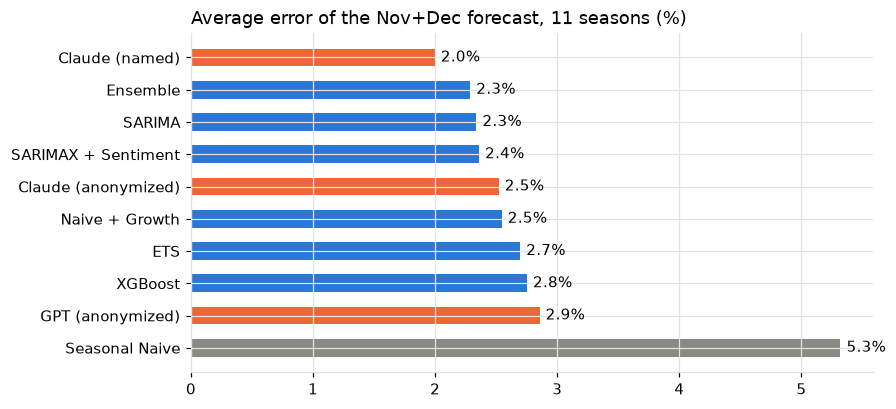

Holiday error by category (%):


model,Claude (anonymized),Claude (named),ETS,Ensemble,GPT (anonymized),Naive + Growth,SARIMA,SARIMAX + Sentiment,Seasonal Naive,XGBoost
category,,,,,,,,,,
clothing,1.78,1.25,1.28,1.07,1.92,2.72,0.92,1.44,4.92,2.06
ecommerce,2.11,1.99,3.90,2.69,2.31,2.21,3.26,3.07,9.62,3.56
electronics,4.64,4.81,4.71,4.25,5.74,4.75,4.43,4.16,6.23,4.36
general,1.95,1.45,1.72,1.88,2.10,2.05,2.07,2.07,3.41,1.97
grocery,1.50,1.24,1.30,1.16,1.08,1.29,1.11,1.11,3.61,1.81
hobby,3.88,2.10,4.39,3.48,4.94,3.03,3.04,3.11,5.35,3.95
total,1.78,1.13,1.57,1.48,1.89,1.78,1.53,1.56,4.10,1.56


In [10]:
d = s_all['holiday_APE'].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(d.index, d.values * 100, height=0.55,
        color=[GRAY if m == 'Seasonal Naive' else ORANGE if m.startswith(('Claude', 'GPT')) else BLUE for m in d.index])
for i, v in enumerate(d.values): ax.text(v * 100 + 0.05, i, f'{v:.1%}', va='center')
ax.set_title('Average error of the Nov+Dec forecast, 11 seasons (%)', loc='left'); plt.show()

print('Holiday error by category (%):')
(po.pivot_table(index='category', columns='model', values='holiday_ape') * 100).round(2)

Claude (anonymized)    vs Claude (named)      : Claude (named) better in 65% of 77, mean diff +0.52 pts, p = 0.0019
Claude (anonymized)    vs Ensemble            : Ensemble better in 57% of 77, mean diff +0.23 pts, p = 0.0785
GPT (anonymized)       vs Ensemble            : Ensemble better in 61% of 77, mean diff +0.57 pts, p = 0.0040
GPT (anonymized)       vs Claude (anonymized) : Claude (anonymized) better in 57% of 77, mean diff +0.33 pts, p = 0.2237
SARIMAX + Sentiment    vs SARIMA              : SARIMA better in 45% of 77, mean diff +0.02 pts, p = 0.5992


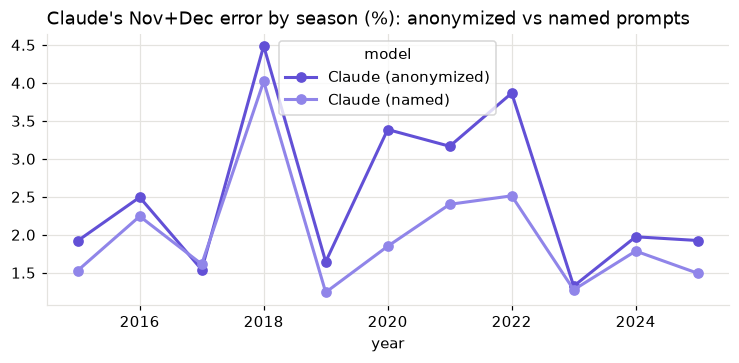

In [11]:
# Paired Wilcoxon signed-rank tests on the same 77 category-seasons
for a, b in [('Claude (anonymized)', 'Claude (named)'), ('Claude (anonymized)', 'Ensemble'),
             ('GPT (anonymized)', 'Ensemble'), ('GPT (anonymized)', 'Claude (anonymized)'),
             ('SARIMAX + Sentiment', 'SARIMA')]:
    t = paired_test(po, a, b)
    if t:
        print(f"{a:22s} vs {b:20s}: {b} better in {t['b_better_share']:.0%} of {t['n']}, "
              f"mean diff {t['mean_diff_pts']:+.2f} pts, p = {t['p_value']:.4f}")

mm = po[po.model.isin(['Claude (anonymized)', 'Claude (named)'])].pivot_table(index='year', columns='model', values='holiday_ape')
ax = (mm * 100).plot(marker='o', figsize=(8, 3.2), color=['#6250d6', '#9085e9'])
ax.set_title("Claude's Nov+Dec error by season (%): anonymized vs named prompts", loc='left'); plt.show()

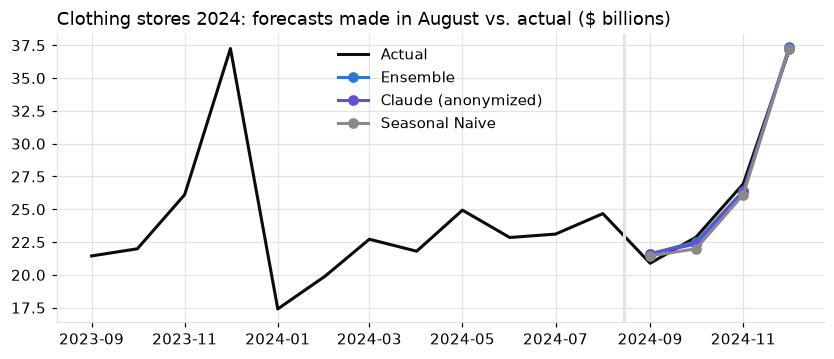

In [12]:
# Replay one season: clothing stores, 2024
cat, yr = 'clothing', 2024
fig, ax = plt.subplots(figsize=(9, 3.4))
h = panel[cat].loc[f'{yr-1}-09':f'{yr}-12']
ax.plot(h.index, h / 1000, color=INK, label='Actual')
for m, col in [('Ensemble', BLUE), ('Claude (anonymized)', '#6250d6'), ('Seasonal Naive', GRAY)]:
    d = bt_all[(bt_all.category == cat) & (bt_all.year == yr) & (bt_all.model == m)]
    ax.plot(d.date, d['mean'] / 1000, marker='o', color=col, label=m)
ax.axvline(pd.Timestamp(f'{yr}-08-15'), color=GRID)
ax.set_title(f'Clothing stores {yr}: forecasts made in August vs. actual ($ billions)', loc='left'); ax.legend(frameon=False); plt.show()

## 7. The 2026 holiday forecast

In [13]:
hol = f26_all[f26_all.date.dt.month >= 11].groupby(['category', 'model'])['mean'].sum().unstack()
ly = panel.loc['2025-11':'2025-12'].sum()
growth = hol.div(ly[hol.index], axis=0) - 1
table = pd.DataFrame({'Nov+Dec 2025 actual ($B)': (ly[hol.index] / 1000).round(1),
                      'Nov+Dec 2026 forecast ($B)': (hol['Ensemble'] / 1000).round(1),
                      'Growth (Ensemble)': (growth['Ensemble'] * 100).round(1).astype(str) + '%'})
display(table)
print('Growth by model (%):'); display((growth * 100).round(1))

# Early reality check: September 2026 total retail was published after our August origin
sep = f26_all[(f26_all.category == 'total') & (f26_all.date == '2026-09-01')][['model', 'mean', 'actual']]
sep.assign(error=lambda d: (d['mean'] / d['actual'] - 1).map('{:+.1%}'.format))

,Nov+Dec 2025 actual ($B),Nov+Dec 2026 forecast ($B),Growth (Ensemble)
category,,,
clothing,68.0,70.0,2.9%
ecommerce,258.5,283.3,9.6%
electronics,18.2,19.3,5.8%
general,179.1,185.7,3.7%
grocery,175.7,177.7,1.1%
hobby,20.8,22.4,7.7%
total,1314.7,1383.1,5.2%


Growth by model (%):


model,Claude (named),ETS,Ensemble,GPT (named),Naive + Growth,SARIMA,SARIMAX + Sentiment,Seasonal Naive,XGBoost
category,,,,,,,,,
clothing,3.8,0.3,2.9,4.3,4.3,4.2,4.6,0.0,4.2
ecommerce,7.9,8.8,9.6,8.7,8.9,10.7,10.4,0.0,9.3
electronics,6.7,4.8,5.8,6.7,7.2,6.4,6.6,0.0,6.3
general,2.7,3.3,3.7,3.4,3.4,4.0,4.0,0.0,3.9
grocery,0.6,0.3,1.1,0.9,0.5,1.4,1.5,0.0,1.5
hobby,8.1,4.9,7.7,9.2,10.8,8.3,8.3,0.0,9.9
total,4.5,4.5,5.2,4.6,5.9,5.5,5.5,0.0,5.6


,model,mean,actual,error
0,Seasonal Naive,595443.000000,635056.0,-6.2%
4,Naive + Growth,630408.363929,635056.0,-0.7%
8,ETS,619903.891428,635056.0,-2.4%
12,SARIMA,622676.778078,635056.0,-1.9%
16,SARIMAX + Sentiment,622542.452905,635056.0,-2.0%
140,XGBoost,630023.894811,635056.0,-0.8%
192,Ensemble,624186.949882,635056.0,-1.7%
196,Claude (named),622000.000000,635056.0,-2.1%
200,GPT (named),622609.000000,635056.0,-2.0%


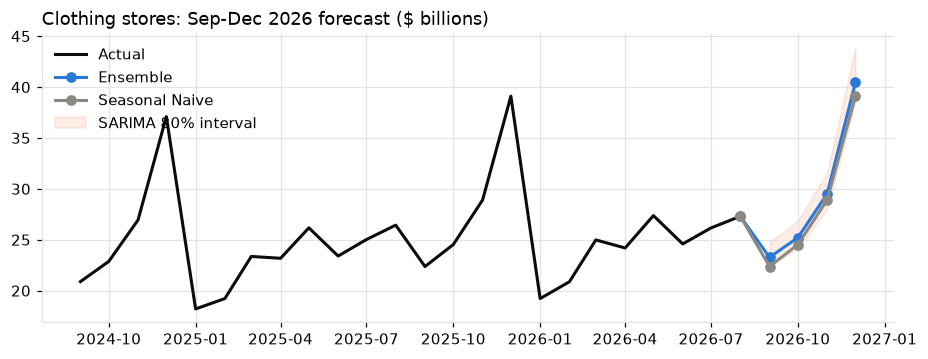

In [14]:
cat = 'clothing'
fig, ax = plt.subplots(figsize=(10, 3.4))
h = panel[cat].loc['2024-09':'2026-08']
ax.plot(h.index, h / 1000, color=INK, label='Actual')
fcc = f26_all[f26_all.category == cat]
for m, col in [('Ensemble', BLUE), ('Seasonal Naive', GRAY)]:
    d = fcc[fcc.model == m]
    ax.plot([h.index[-1]] + list(d.date), [h.iloc[-1] / 1000] + list(d['mean'] / 1000), marker='o', color=col, label=m)
sb = fcc[fcc.model == 'SARIMA']
ax.fill_between(sb.date, sb.lo80 / 1000, sb.hi80 / 1000, color=ORANGE, alpha=0.12, label='SARIMA 80% interval')
ax.set_title('Clothing stores: Sep-Dec 2026 forecast ($ billions)', loc='left'); ax.legend(frameon=False); plt.show()

## 8. From forecast to order (the Holiday Planner rule)

Expected sales = the store's own Nov+Dec 2025 sales × (1 + national category growth).
Uncertainty σ = √(national forecast error² + store volatility²), where the national error is the root-mean-square of
the ensemble's past holiday % errors for that category (excluding COVID seasons).
Safety buffer = z × σ × expected sales (z for the chosen service level). Order = max(0, expected + buffer − on hand − on order).

Example: a clothing boutique sold 5,000 units last Nov+Dec, has 1,200 on hand, wants a 90% chance of not running out,
and its sales typically miss plan by ±10%.

In [15]:
last, on_hand, on_order, service, store_sd = 5000, 1200, 0, 0.90, 0.10
g = growth.loc['clothing', 'Ensemble']
pe = po[(po.model == 'Ensemble') & (po.category == 'clothing') & (~po.year.isin(COVID_YEARS))]['holiday_pe']
sigma_nat = np.sqrt((pe ** 2).mean()); sigma = np.sqrt(sigma_nat ** 2 + store_sd ** 2)
expected = last * (1 + g); safety = norm.ppf(service) * sigma * expected
order = max(0, expected + safety - on_hand - on_order)
print(f'national growth {g:+.1%} | national error {sigma_nat:.1%} | total sigma {sigma:.1%}')
print(f'expected {expected:,.0f} + safety {safety:,.0f} - on hand {on_hand:,} = recommended order {np.ceil(order):,.0f} units')

national growth +2.9% | national error 1.2% | total sigma 10.1%
expected 5,144 + safety 664 - on hand 1,200 = recommended order 4,609 units


## 9. Conclusions

1. **Forecasting beats habit.** Every model roughly halves the error of "same as last year"; the ensemble is the most
   accurate classical/ML model.
2. **Consumer sentiment does not help** - adding it to SARIMA does not reduce the error.
3. **LLMs: hindsight, not foresight.** Told the category and the year, Claude looks like the best forecaster; with them
   hidden its error rises and the advantage disappears - the gap is largest in 2020-2022, when knowing what happened
   helps most. Fairly tested (anonymized), Claude and GPT are good forecasters but not better than our ensemble.
4. **2026:** a solid holiday season, led by e-commerce, which keeps taking share from stores.
5. **Limits:** national category data (not a single store), today's revised data (not real-time vintages), 11 seasons is a
   small sample, and no inventory-cost data - so no claims about money saved.

**AI tools used.** Claude Code wrote most of the code from our research questions and design decisions; we reviewed
it and checked results against the raw data. Claude Opus 5.5 and GPT-5.5 are forecasters in the comparison, and
Claude powers the dashboard's AI advisor.